In [4]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Defining the columns based on the standard SAheart dataset structure
columns = ['sbp', 'tobacco', 'ldl', 'adiposity', 'famhist', 'typea', 'obesity', 'alcohol', 'age', 'chd']

# Load the file verbatim as requested
df = pd.read_csv('inputDataset.txt', sep='\t', header=None, names=columns) 

# We use replace() so it works whether the data is text ('Present'/'Absent') or already numeric
df['famhist'] = df['famhist'].replace({'Present': 1, 'Absent': 0})
# Ensure the column is numeric for our math matrices
df['famhist'] = pd.to_numeric(df['famhist'])

df.head()

,sbp,tobacco,ldl,adiposity,famhist,typea,obesity,alcohol,age,chd
0,160,12.00,5.73,23.11,1,49,25.30,97.20,52,1
1,144,0.01,4.41,28.61,0,55,28.87,2.06,63,1
2,118,0.08,3.48,32.28,1,52,29.14,3.81,46,0
3,170,7.50,6.41,38.03,1,51,31.99,24.26,58,1
4,134,13.60,3.50,27.78,1,60,25.99,57.34,49,1


In [5]:
# Data Partitioning: Isolate target and features
X = df.drop('chd', axis=1).to_numpy()
y = df['chd'].to_numpy()

# Split the system into 70% Training Data and 30% Testing Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

Training features shape: (323, 9)
Testing features shape: (139, 9)


In [6]:
# Defining Pure Mathematical matrix implementations of LDA and QDA

class NumpyLDA:
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.classes = np.unique(y)
        self.priors = np.zeros(len(self.classes))
        self.means = np.zeros((len(self.classes), n_features))
        self.pooled_cov = np.zeros((n_features, n_features))

        for idx, c in enumerate(self.classes):
            X_c = X[y == c]
            self.priors[idx] = X_c.shape[0] / n_samples
            self.means[idx, :] = np.mean(X_c, axis=0)
            # Accumulate the covariance, scaled by (N_c - 1)
            self.pooled_cov += np.cov(X_c, rowvar=False) * (X_c.shape[0] - 1)
        
        # Divide by (N - K) to get the pooled covariance matrix
        self.pooled_cov /= (n_samples - len(self.classes))

    def predict(self, X):
        # Inverse of pooled covariance matrix
        inv_cov = np.linalg.inv(self.pooled_cov)
        y_pred = []
        for x in X:
            scores = []
            for idx, c in enumerate(self.classes):
                mean = self.means[idx]
                # Linear discriminant function
                score = x.T @ inv_cov @ mean - 0.5 * mean.T @ inv_cov @ mean + np.log(self.priors[idx])
                scores.append(score)
            y_pred.append(self.classes[np.argmax(scores)])
        return np.array(y_pred)


class NumpyQDA:
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.classes = np.unique(y)
        self.priors = np.zeros(len(self.classes))
        self.means = np.zeros((len(self.classes), n_features))
        self.covariances = []

        for idx, c in enumerate(self.classes):
            X_c = X[y == c]
            self.priors[idx] = X_c.shape[0] / n_samples
            self.means[idx, :] = np.mean(X_c, axis=0)
            # Compute distinct covariance for each class
            self.covariances.append(np.cov(X_c, rowvar=False))

    def predict(self, X):
        y_pred = []
        for x in X:
            scores = []
            for idx, c in enumerate(self.classes):
                mean = self.means[idx]
                cov = self.covariances[idx]
                inv_cov = np.linalg.inv(cov)
                # Quadratic discriminant function
                score = -0.5 * np.log(np.linalg.det(cov)) - 0.5 * (x - mean).T @ inv_cov @ (x - mean) + np.log(self.priors[idx])
                scores.append(score)
            y_pred.append(self.classes[np.argmax(scores)])
        return np.array(y_pred)

In [7]:
# Instantiate and fit the models
lda_model = NumpyLDA()
qda_model = NumpyQDA()

lda_model.fit(X_train, y_train)
qda_model.fit(X_train, y_train)

# Predict on unseen testing dataset
y_pred_lda = lda_model.predict(X_test)
y_pred_qda = qda_model.predict(X_test)

--- LDA Classification Report ---
              precision    recall  f1-score   support

           0       0.76      0.84      0.80        90
           1       0.64      0.51      0.57        49

    accuracy                           0.73       139
   macro avg       0.70      0.68      0.68       139
weighted avg       0.72      0.73      0.72       139


--- QDA Classification Report ---
              precision    recall  f1-score   support

           0       0.72      0.84      0.78        90
           1       0.58      0.39      0.46        49

    accuracy                           0.68       139
   macro avg       0.65      0.62      0.62       139
weighted avg       0.67      0.68      0.67       139



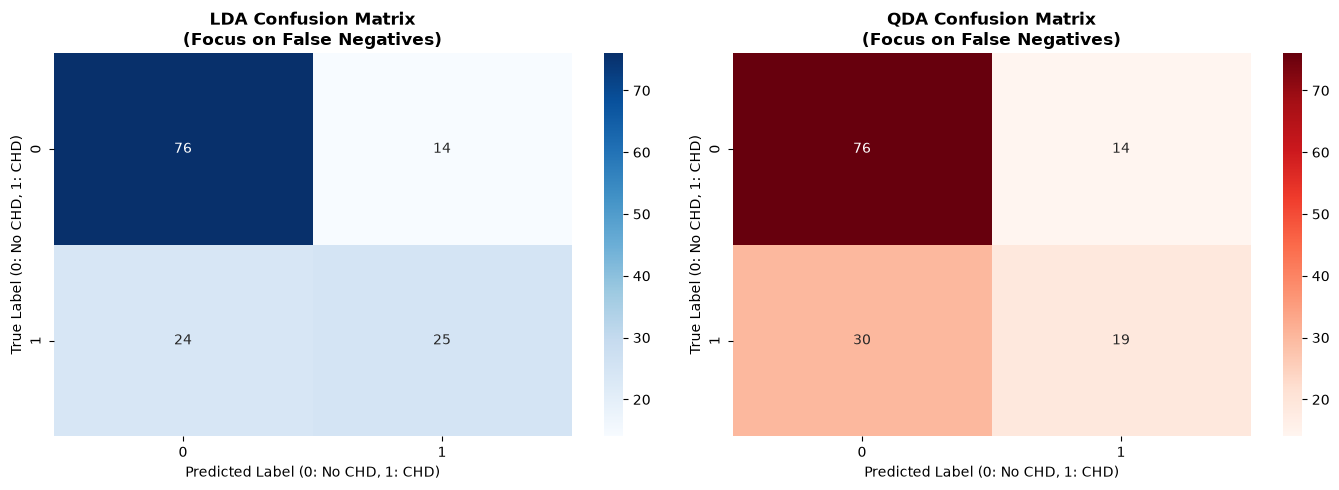

In [8]:
#Comparative Performance Audit (Reports & Heatmaps)
# Generate classification reports
print("--- LDA Classification Report ---")
print(classification_report(y_test, y_pred_lda))

print("\n--- QDA Classification Report ---")
print(classification_report(y_test, y_pred_qda))

# Plot side-by-side Seaborn Confusion Matrix Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# LDA Heatmap
sns.heatmap(confusion_matrix(y_test, y_pred_lda), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('LDA Confusion Matrix\n(Focus on False Negatives)', fontweight='bold')
axes[0].set_xlabel('Predicted Label (0: No CHD, 1: CHD)')
axes[0].set_ylabel('True Label (0: No CHD, 1: CHD)')

# QDA Heatmap
sns.heatmap(confusion_matrix(y_test, y_pred_qda), annot=True, fmt='d', cmap='Reds', ax=axes[1])
axes[1].set_title('QDA Confusion Matrix\n(Focus on False Negatives)', fontweight='bold')
axes[1].set_xlabel('Predicted Label (0: No CHD, 1: CHD)')
axes[1].set_ylabel('True Label (0: No CHD, 1: CHD)')

plt.tight_layout()
plt.show()